
---
date: "2026-10-25"
date-modified: last-modified
format:
  html:
    toc: true
---


# Maximum-Weight Bipartite Matching

**Prerequisites:** [Integer Programs and LP Relaxation](integer-programming.ipynb)

## 1\. The Problem

::: {#def-perfect-matching}
## Perfect Matching

Let $G = (V, E)$ be a **bipartite graph**: $V = X \cup Y$ with $X \cap Y = \emptyset$, and every edge joins a vertex of $X$ to a vertex of $Y$. A **perfect matching** is a set $M \subseteq E$ such that every vertex lies on exactly one edge of $M$. Given weights $w_e \in \mathbb{R}$ $(e \in E)$, the **maximum-weight perfect matching problem** asks for a perfect matching maximizing $w(M) = \sum_{e \in M} w_e$. For a vertex $v$, let $\delta(v)$ be the set of edges containing $v$.
:::

A perfect matching pairs every vertex of $X$ with a vertex of $Y$, so it can exist only if $|X| = |Y|$.

::: {#exm-greedy-fails}
## Greedy Assignment Fails

Let $X = \{A, B, C\}$, $Y = \{1, 2, 3\}$ and edges $A1, A2, B1, C1, C3$ with weights $9, 5, 8, 7, 6$. Assign $A, B, C$ in turn to the best free neighbour: $A \to 1$ (weight $9$); the only neighbour of $B$ is $1$, already taken, so the greedy procedure gets stuck. But a perfect matching exists: $B$ must use $B1$, then $C$ must use $C3$ and $A$ must use $A2$, giving $\{A2, B1, C3\}$ of weight $19$.
:::

## 2\. Integer Program and Relaxation

::: {#prp-matching-ip}
## Matchings as 0–1 Vectors

A vector $x \in \{0,1\}^E$ satisfies $\sum_{e \in \delta(v)} x_e = 1$ for every $v \in V$ if and only if $M = \{e : x_e = 1\}$ is a perfect matching. Hence the maximum-weight perfect matching problem is the IP
$$
\text{maximize } \sum_{e \in E} w_ex_e \quad \text{subject to } \sum_{e \in \delta(v)} x_e = 1\ \ (v \in V), \quad x \in \{0, 1\}^E,
$$
and its LP relaxation replaces $x \in \{0,1\}^E$ by $0 \le x_e \le 1$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-matching-ip
For $x \in \{0,1\}^E$, $\sum_{e \in \delta(v)} x_e$ is the number of edges of $M$ containing $v$. It equals $1$ for all $v$ iff $M$ is a perfect matching, and then $\sum_e w_ex_e = w(M)$. $\blacksquare$
:::

::: {#lem-fractional-cycle}
## Fractional Edges Contain an Even Cycle

Let $x$ be feasible for the relaxation and not integral, and let $F = \{e : 0 < x_e < 1\}$ be the set of fractional edges. Then the edges of $F$ contain a cycle, and every cycle in a bipartite graph has even length.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-fractional-cycle
*Every vertex on a fractional edge lies on at least two.* If $e \in F$ contains $v$, then $\sum_{e' \in \delta(v),\, e' \ne e} x_{e'} = 1 - x_e \in (0, 1)$ is not an integer, so some $e' \ne e$ in $\delta(v)$ has $x_{e'} \notin \{0,1\}$, i.e. $e' \in F$.

*A cycle.* Since $x$ is not integral, $F \ne \emptyset$. Start at an endpoint $v_0$ of an edge of $F$ and walk along it to $v_1$. Having arrived at $v_k$ along an edge of $F$, leave along a *different* edge of $F$ at $v_k$ (it exists by the first step). Since $V$ is finite, some vertex is visited twice; let $v_k = v_j$ with $j < k$ be the first repetition, so $v_0, \dots, v_{k-1}$ are distinct. Here $k \ne j + 1$ (an edge has two distinct ends) and $k \ne j + 2$ (the edge from $v_{k-1}$ back to $v_j = v_{k-2}$ would be the edge just used). So $k - j \ge 3$, and $v_j, v_{j+1}, \dots, v_{k-1}, v_j$ is a cycle all of whose edges lie in $F$.

*Even length.* The vertices of a cycle alternate between $X$ and $Y$, and the cycle returns to its starting side, so it has an even number of edges. $\blacksquare$
:::

::: {#thm-matching-integral}
## The Relaxation Has an Integral Optimum

If the relaxation of @prp-matching-ip is feasible, then it has an optimal solution, and it has an optimal solution in $\{0, 1\}^E$. More precisely, every optimal solution can be turned into an integral optimal solution by the following step, repeated at most $|E|$ times: choose an even cycle $e_1, \dots, e_{2k}$ of fractional edges, add $\varepsilon$ to $x_{e_1}, x_{e_3}, \dots$ and subtract $\varepsilon$ from $x_{e_2}, x_{e_4}, \dots$, where $\varepsilon \ge 0$ is as large as possible keeping $0 \le x \le 1$.

Consequently the maximum weight of a perfect matching equals the optimal value of the LP relaxation, and a bipartite graph has a perfect matching if and only if the relaxation is feasible.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-matching-integral
*Existence.* The feasible set is nonempty, closed (defined by non-strict linear conditions) and bounded (contained in $[0, 1]^E$), so it is [compact](compactness.ipynb), and the continuous function $x \mapsto w^{\mathsf T}x$ attains its maximum on it ([continuity and compactness](continuity-and-compactness.ipynb)).

*One step.* Let $x$ be optimal and not integral, and take an even cycle $e_1, \dots, e_{2k}$ in $F$ (@lem-fractional-cycle). Define $d \in \mathbb{R}^E$ by $d_{e_i} = (-1)^{i+1}$ and $d_e = 0$ for edges not on the cycle. Each vertex of the cycle lies on exactly two cycle edges, which are consecutive and so have opposite signs; vertices off the cycle lie on no cycle edge. Hence $\sum_{e \in \delta(v)} d_e = 0$ for all $v$, and $x + \varepsilon d$ satisfies all equations for every $\varepsilon \in \mathbb{R}$. Let
$$
\varepsilon_0 = \min_{e \text{ on the cycle}} \min(x_e, 1 - x_e) > 0 .
$$
For $|\varepsilon| \le \varepsilon_0$ the vector $x + \varepsilon d$ is feasible, with value $w^{\mathsf T}x + \varepsilon\, w^{\mathsf T}d$. If $w^{\mathsf T}d \ne 0$, then $\varepsilon = \varepsilon_0$ or $\varepsilon = -\varepsilon_0$ gives a larger value, contradicting optimality. So $w^{\mathsf T}d = 0$, and $x + \varepsilon d$ is optimal for every $\varepsilon$ for which it is feasible.

Let $\varepsilon_1 \ge 0$ be the largest $\varepsilon$ with $0 \le x + \varepsilon d \le 1$, namely the minimum of $1 - x_e$ over the cycle edges with $d_e = +1$ and of $x_e$ over those with $d_e = -1$; it is finite and $\ge \varepsilon_0 > 0$. Then $x' = x + \varepsilon_1 d$ is optimal, coordinates off the cycle are unchanged, and at least one cycle coordinate has become $0$ or $1$. So $x'$ has fewer fractional coordinates than $x$.

*Iteration.* Each step decreases the number of fractional coordinates, so after at most $|E|$ steps we reach an optimal $x \in \{0,1\}^E$, which by @prp-matching-ip is a perfect matching of weight equal to the LP optimum. For the last claim, take $w = 0$: if the relaxation is feasible, it has an integral optimal (in particular feasible) solution, which is a perfect matching; the converse is clear. $\blacksquare$
:::

::: {.callout-warning}
## Bipartiteness Is Needed
In a graph consisting of two disjoint triangles, every vertex lies on two edges, so $x_e = \frac12$ for all edges satisfies $\sum_{e \in \delta(v)} x_e = 1$. But there is no perfect matching (a triangle has an odd number of vertices). The proof fails because the cycles of fractional edges are odd: alternating signs around an odd cycle do not cancel at the starting vertex.
:::

LP optimal value: 13.0
fractional solution value: 13.0
after rounding: ['A1', 'B2', 'C3']  value: 13.0


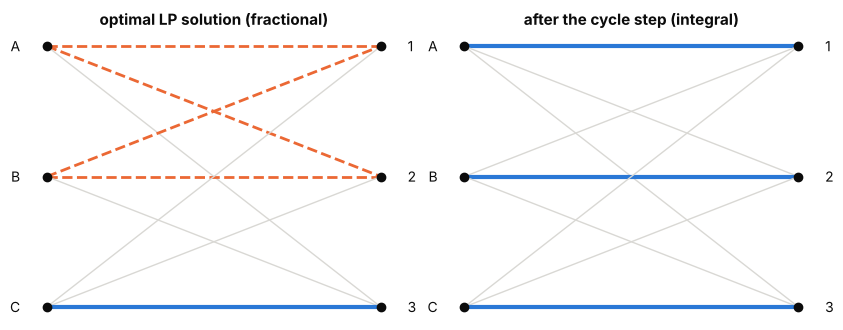

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#d9d8d4", "#a3a29a"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from scipy.optimize import linprog

X, Y = ["A", "B", "C"], ["1", "2", "3"]
W = np.array([[4, 4, 1], [4, 4, 1], [1, 1, 5]], float)       # complete bipartite graph K_{3,3}
E = [(i, j) for i in range(3) for j in range(3)]
w = np.array([W[e] for e in E])
A_eq = [[1 if e[0] == i else 0 for e in E] for i in range(3)] + [[1 if e[1] == j else 0 for e in E] for j in range(3)]
lp = linprog(-w, A_eq=A_eq, b_eq=np.ones(6), bounds=[(0, 1)] * 9)
print("LP optimal value:", -lp.fun)

# a fractional optimal solution: the average of the two optimal matchings {A1,B2,C3} and {A2,B1,C3}
x = np.zeros(9)
for M in [[(0, 0), (1, 1), (2, 2)], [(0, 1), (1, 0), (2, 2)]]:
    for e in M: x[E.index(e)] += 0.5
print("fractional solution value:", w @ x)

def round_matching(x, tol=1e-12):
    """Cycle-shifting procedure of the theorem; returns an integral solution of the same value."""
    x = x.copy()
    while True:
        frac = [k for k in range(len(E)) if tol < x[k] < 1 - tol]
        if not frac:
            return x
        # walk along fractional edges, never reusing the edge just used, until a vertex repeats
        node = ("X", E[frac[0]][0]); path_nodes, path_edges, last = [node], [], None
        while True:
            side, idx = node
            k = next(k for k in frac if k != last and (E[k][0] if side == "X" else E[k][1]) == idx)
            node = ("Y", E[k][1]) if side == "X" else ("X", E[k][0])
            path_edges.append(k); last = k
            if node in path_nodes:
                cyc = path_edges[path_nodes.index(node):]
                break
            path_nodes.append(node)
        d = np.zeros(len(E)); d[cyc[0::2]] = 1; d[cyc[1::2]] = -1
        eps = min([1 - x[k] for k in cyc if d[k] > 0] + [x[k] for k in cyc if d[k] < 0])
        x += eps * d

xi = round_matching(x)
print("after rounding:", [X[E[k][0]] + Y[E[k][1]] for k in range(9) if xi[k] > 0.5], " value:", w @ xi)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, sol, title in [(axes[0], x, "optimal LP solution (fractional)"), (axes[1], xi, "after the cycle step (integral)")]:
    for k, (i, j) in enumerate(E):
        style = dict(color=BLUE, lw=3) if sol[k] > 0.99 else dict(color=ORANGE, lw=2, ls="--") if sol[k] > 1e-9 else dict(color=GRID, lw=1)
        ax.plot([0, 1], [2 - i, 2 - j], **style)
    for i in range(3):
        ax.text(-0.08, 2 - i, X[i], ha="right", va="center"); ax.text(1.08, 2 - i, Y[i], ha="left", va="center")
    ax.plot([0] * 3, range(3), "o", color=INK); ax.plot([1] * 3, range(3), "o", color=INK)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()